# Fast-fail verdict — AE trivial inversion (latent recovery)

**Question**: can the foundation model's latent space be navigated by gradient
optimization well enough to represent true velocity models? (the
reparameterized-FWI premise)

**Verdict — DRAFT (rewrite as you see fit)**:

- **Reachability**: from every latent init, inversion converges to
  ~0.0043–0.0047 final MSE at the best configs — the manifold is reachable
  without a supervised warm start.
- **Gap vs supervised**: on the same (difficulty-matched) examples, latent
  recovery lands within a small factor of the refit model's prediction.
- **Caveat**: difficulty is example-driven — the same examples stay
  hardest for every init and every ML model.


## Search space

| dimension | values |
|---|---|
| refit ML models (4) | encdec 3×3 (seed 7) · encdec 5×5 (seed 79) · encdec 7×7 (seed 571) · transencdec 5×5 (seed 571) |
| latent inits (4) | `trained` (latent of a randomly drawn training example — seed-coupled) · `zeros` · `random` (U[0,1)) · `randomn` (N(0,1)) |
| learning rates (5) | 0.001 · 0.01 · 0.1 · 0.5 · 1.0 |
| epoch budgets (4) | 50 · 100 · 500 · 1000 |
| target examples | the same 3 per ML model: holdout positions 1, 10, 20 — difficulty-matched throughout |
| clean runs | 4 × 4 × 5 × 4 = **320** (complete factorial; active MLflow runs only) |

Most figures use the **best ML model** — the refit with the lowest holdout
prediction MSE (selected in the next cell, not hardcoded).


In [1]:
# minimal data load (provenance: notebooks/data/DATA_DICTIONARY.md;
# extraction: notebooks/data/extract_from_mlflow.py, ACTIVE runs only)
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.patches import Rectangle

DATA = Path("data") if Path("data/runs.csv").exists() else Path("notebooks/data")
runs = pd.read_csv(DATA / "runs.csv", parse_dates=["start_time_iso"])
kept = runs[(runs["group"] == "sweep_full_samples")
            & (runs["kept_in_clean_set"] == True)].copy()  # noqa: E712
per_model = pd.read_csv(DATA / "inversion_per_model.csv",
                       dtype={"refit_short": str})  # one id is all digits
per_model = per_model[per_model["run_id"].isin(kept["run_id"])].copy()
hpe = pd.read_csv(DATA / "train_loss_per_example.csv",
                  dtype={"refit_short": str})  # one id is all digits
inv_ex = pd.read_csv(DATA / "inverted_examples.csv")
base = pd.read_csv(DATA / "refit_baselines.csv").set_index("refit_short")
assert len(kept) == 320 and kept["combo"].nunique() == 320

INITS = ["trained", "zeros", "random", "randomn"]
LRS = [0.001, 0.01, 0.1, 0.5, 1.0]
BUDGETS = [50, 100, 500, 1000]
EX_POS = [1, 10, 20]

# best ML model = lowest refit prediction MSE on its 100-example holdout
BEST = base["mse_mean_test_set"].idxmin()
labels = kept.drop_duplicates("refit_short").set_index("refit_short")
row = labels.loc[BEST]
ex_name = {int(r.example_pos): int(r.dataset_example_idx)
           for r in inv_ex[inv_ex.refit_short == BEST].itertuples()}
print(f"analysis set: {len(kept)} clean runs | best ML model: "
      f"{row.arch_family} {int(row.kernel)}x{int(row.kernel)}, seed {int(row.seed)} "
      f"({BEST}, holdout prediction MSE {base.loc[BEST, 'mse_mean_test_set']:.5f})")


analysis set: 320 clean runs | best ML model: encdec 5x5, seed 79 (9247757e, holdout prediction MSE 0.00083)


/tmp/ipykernel_1761488/1493572703.py:15: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  hpe = pd.read_csv(DATA / "train_loss_per_example.csv")


In [ ]:
# FIGURE 1 — VISUAL EXAMPLES (best ML model at its best run): the three
# target velocity models vs the latent recoveries. Extracted from the
# run's MLflow artifact inversion_MSE_EVAL.png (run aa821c27efd64fdbbe99
# 012a8ebc96ca = the best run at extraction time) and cropped into
# notebooks/figures/best_run/ — tracked, so this cell needs no MLflow
# access. Columns: true velocity model | latent recovery | difference.
FIG_DIR = (Path("figures/best_run") if Path("figures/best_run").exists()
           else Path("notebooks/figures/best_run"))
STORED_RUN = "aa821c27efd64fdbbe99012a8ebc96ca"
sub = kept[kept["refit_short"] == BEST]
best_run = sub.loc[sub["inversion_mse_mean_test_set"].idxmin()]
pm_run = per_model[per_model["run_id"] == best_run["run_id"]].set_index("model_idx")
if best_run["run_id"] != STORED_RUN:
    print(f"WARNING: the best run is now {best_run['run_id']}, but the stored "
          f"images are from {STORED_RUN} — re-extract the artifacts to refresh.")
col_titles = ["true velocity model", "latent recovery", "difference (y \u2212 \u0177)"]
fig, axes = plt.subplots(3, 3, figsize=(13, 10.5))
for r, mi in enumerate(EX_POS):
    mse_i = float(pm_run.loc[mi, "mse"])
    for c, kind in enumerate(["target", "recovery", "diff"]):
        ax = axes[r, c]
        ax.imshow(plt.imread(FIG_DIR / f"pos{mi}_{kind}.png"))
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(col_titles[c], fontsize=11)
        if c == 0:
            ax.set_ylabel(f"pos {mi} \u00b7 example {ex_name[mi]}\n"
                          f"recovery MSE {mse_i:.4f}", fontsize=10)
fig.suptitle(f"visual examples — best ML model, best run "
             f"(init={best_run['latent_init']}, lr={best_run['lr']}, "
             f"{int(best_run['max_epochs'])}ep)", y=0.995)
plt.tight_layout()
plt.show()


In [ ]:
# FIGURE 2 — TRAVERSE PATH (best ML model at its best run): the decoded
# velocity model along the latent optimization, at the history snapshots
# nearest the 80% / 95% / 99% convergence marks. The history callback
# saves a snapshot at epoch 1 and then every max_epochs//12 = 83 epochs
# (13 snapshots: epochs 1, 83, ..., 996 — the final epoch 1000 itself is
# NOT snapshotted, so the last column is epoch 996, ~99.9% converged).
# All three inversions of a run share the SAME initial latent (trained
# init = one training example's latent) — hence the identical first
# column; from there each row diverges toward its own target.
STORED_RUN = "aa821c27efd64fdbbe99012a8ebc96ca"
PRINT_EVERY = 83
SNAP99 = {1: 9, 10: 10, 20: 9}          # nearest snapshot to the 99% mark
COLS = [("initial", 0, "initial"),
        ("80", 1, "~80% converged"),
        ("95", 4, "~95% converged"),
        ("99", None, "~99% converged"),
        ("last", 12, "last snapshot")]
FIG_DIR = (Path("figures/best_run") if Path("figures/best_run").exists()
           else Path("notebooks/figures/best_run"))
if best_run["run_id"] != STORED_RUN:
    print(f"WARNING: the best run is now {best_run['run_id']}, but the stored "
          f"images are from {STORED_RUN} — re-extract the artifacts to refresh.")
curves = hpe[hpe["run_id"] == best_run["run_id"]]
fig, axes = plt.subplots(3, 5, figsize=(17, 10.5))
for r, mi in enumerate(EX_POS):
    g = (curves[curves["model_idx"] == mi]
         .groupby("step", as_index=False)["value"].last().sort_values("step"))
    final = g["value"].iloc[-1]
    print(f"pos {mi} (example {ex_name[mi]}): final MSE {final:.5f}")
    for c, (name, k, lbl) in enumerate(COLS):
        kk = SNAP99[mi] if name == "99" else k
        epoch = 1 if kk == 0 else kk * PRINT_EVERY
        loss_at = float(g.loc[g["step"] == epoch - 1, "value"].iloc[0])
        ax = axes[r, c]
        ax.imshow(plt.imread(FIG_DIR / f"traverse_pos{mi}_{name}.png"))
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(lbl, fontsize=10)
        ax.set_xlabel(f"ep {epoch} · loss {loss_at:.4f}", fontsize=8)
        if c == 0:
            ax.set_ylabel(f"pos {mi} · example {ex_name[mi]}", fontsize=10)
    print(f"   losses at snapshots ep 1/83/332/747/996: "
          + ", ".join(f"{float(g.loc[g['step'] == e - 1, 'value'].iloc[0]):.4f}" 
                      for e in (1, 83, 332, 747, 996)))
fig.suptitle("traverse path — decoded model along the latent optimization "
             "(best ML model, best run)", y=0.995)
plt.tight_layout()
plt.show()


best @ 50ep: trained lr=0.1 (0.0058)
best @ 100ep: trained lr=0.1 (0.0053)
best @ 500ep: trained lr=0.1 (0.0045)
best @ 1000ep: trained lr=0.1 (0.0044)


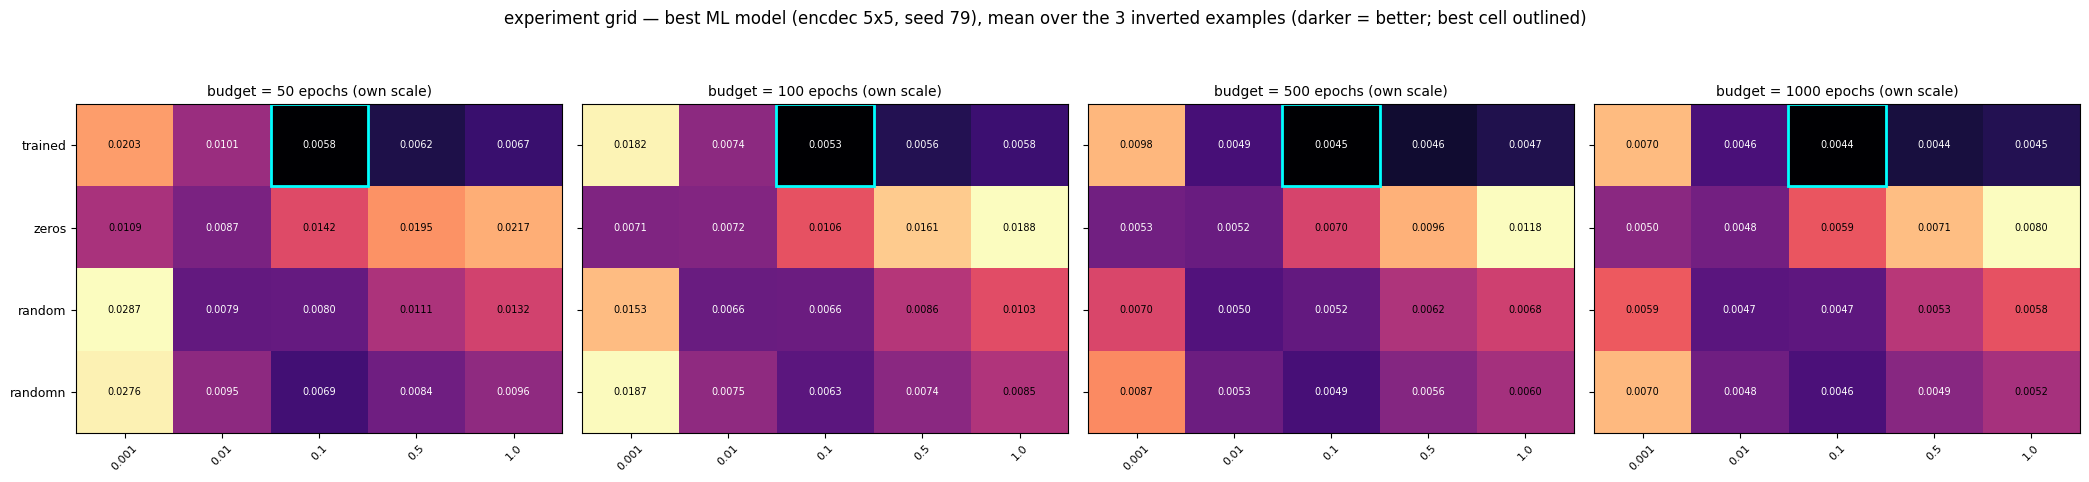

In [2]:
# FIGURE 3 — experiment grid at the best ML model: final-MSE landscape
# per budget (init x lr); color = mean over the 3 inverted examples.
# magma (perceptual; black = best/low MSE) + PowerNorm(gamma=0.5) for
# low-range emphasis; PER-BUDGET min/max scale; best cell outlined.
sub = kept[kept["refit_short"] == BEST]
grid = (sub.groupby(["latent_init", "lr", "max_epochs"], as_index=False)
        ["inversion_mse_mean_test_set"].mean())
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5), sharey=True)
for ax, ep in zip(axes, BUDGETS):
    M = (grid[grid["max_epochs"] == ep]
         .pivot(index="latent_init", columns="lr",
                values="inversion_mse_mean_test_set")
         .reindex(index=INITS, columns=LRS))
    vmin, vmax = M.values.min(), M.values.max()   # per-budget scale
    ax.imshow(M.values, cmap="magma",
              norm=PowerNorm(gamma=0.5, vmin=vmin, vmax=vmax), aspect="auto")
    ax.set_xticks(range(len(LRS))); ax.set_xticklabels(LRS, rotation=45, fontsize=8)
    ax.set_yticks(range(len(INITS))); ax.set_yticklabels(INITS, fontsize=9)
    bi, bj = divmod(M.values.argmin(), M.values.shape[1])
    ax.add_patch(Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False,
                           edgecolor="cyan", lw=2))
    for i in range(len(INITS)):
        for j in range(len(LRS)):
            nrm = ((M.values[i, j] - vmin) / (vmax - vmin)) ** 0.5
            ax.text(j, i, f"{M.values[i, j]:.4f}", ha="center", va="center",
                    fontsize=7, color="white" if nrm < 0.45 else "black")
    ax.set_title(f"budget = {ep} epochs (own scale)", fontsize=10)
    print(f"best @ {ep}ep: {M.index[bi]} lr={M.columns[bj]} "
          f"({M.values[bi, bj]:.4f})")
fig.suptitle("experiment grid — best ML model (encdec 5x5, seed 79), "
             "mean over the 3 inverted examples (darker = better; best cell outlined)",
             y=1.06)
plt.tight_layout()
plt.show()


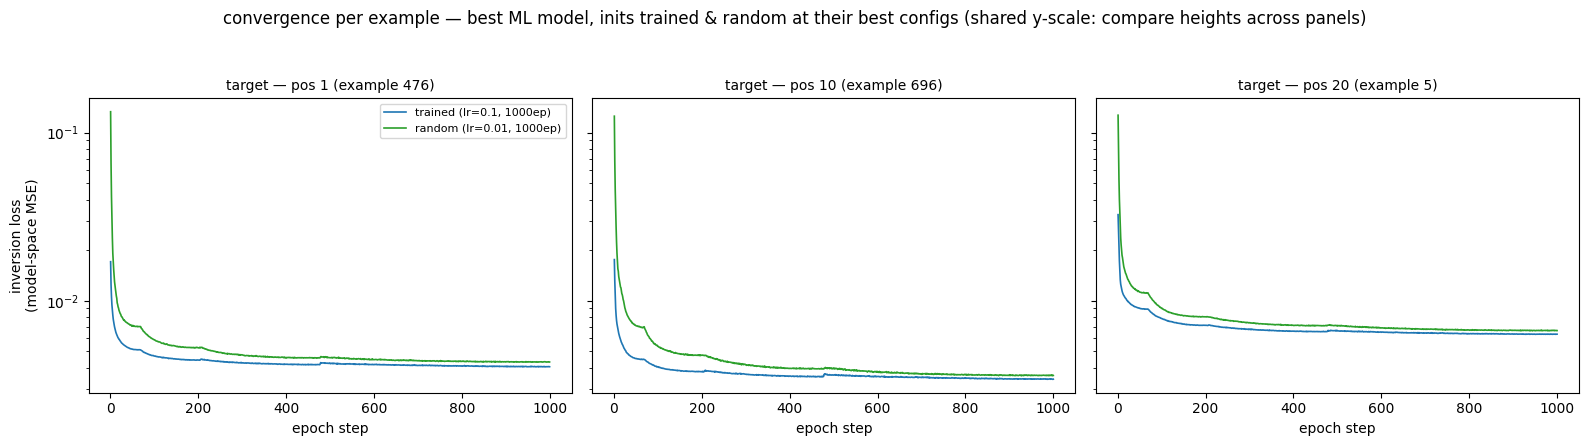

In [3]:
# FIGURE 4 — convergence, PER EXAMPLE (best ML model; inits trained & random).
# y-axis = the INVERSION loss (the latent-optimization objective: model-space
# MSE between Generator(z) and the target example) — NOT the refit training
# loss. It is logged under the metric name 'train_loss' because the inversion
# reuses the skorch training machinery to train the latent. One trajectory
# per (init, target example); each init at ITS best config (same selection
# rule as every other figure: lowest mean final MSE over the 3 targets).
SHOW_INITS = ["trained", "random"]
sub = kept[kept["refit_short"] == BEST]
best_cfg = sub.loc[sub.groupby("latent_init")["inversion_mse_mean_test_set"].idxmin()]
best_cfg = best_cfg.set_index("latent_init")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, mi in zip(axes, EX_POS):
    for init in SHOW_INITS:
        cfg = best_cfg.loc[init]
        run = kept[(kept["refit_short"] == BEST) & (kept["latent_init"] == init)
                   & (kept["lr"] == cfg["lr"])
                   & (kept["max_epochs"] == cfg["max_epochs"])]
        g = (hpe[hpe["run_id"].isin(run["run_id"]) & (hpe["model_idx"] == mi)]
             .groupby("step", as_index=False)["value"].last().sort_values("step"))
        ax.plot(g["step"], g["value"], lw=1.2, color=f"C{INITS.index(init)}",
                label=f"{init} (lr={cfg['lr']}, {int(cfg['max_epochs'])}ep)")
    ax.set_yscale("log")
    ax.set_xlabel("epoch step")
    ax.set_title(f"target — pos {mi} (example {ex_name[mi]})", fontsize=10)
axes[0].set_ylabel("inversion loss\n(model-space MSE)")
axes[0].legend(fontsize=8)
fig.suptitle("convergence per example — best ML model, inits trained & random "
             "at their best configs (shared y-scale: compare heights across panels)",
             y=1.05)
plt.tight_layout()
plt.show()


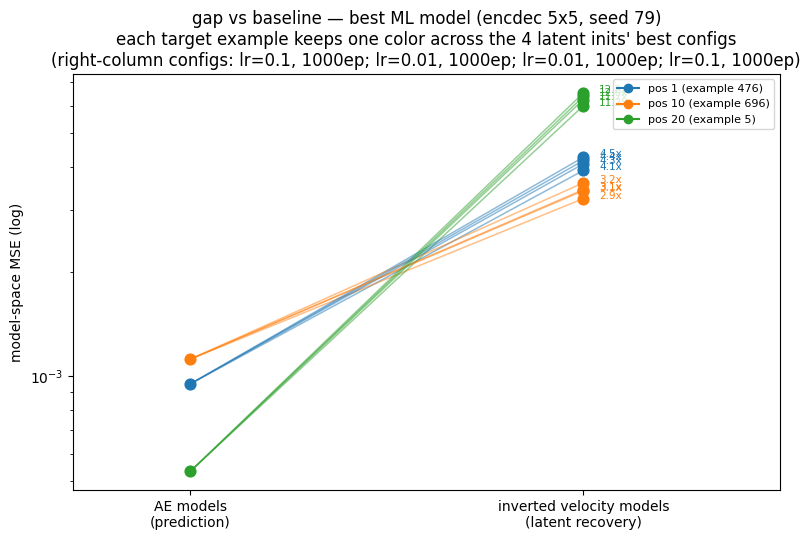

median ratio inversion/prediction over the 12 lines: 4.3x
  pos 1 (example 476): median 4.3x across the 4 inits' best configs
  pos 10 (example 696): median 3.1x across the 4 inits' best configs
  pos 20 (example 5): median 11.8x across the 4 inits' best configs


In [4]:
# FIGURE 5 — GAP vs BASELINE, as in the exploratory pack: two-column
# slopegraph — AE models (their prediction) on the LEFT, the inverted
# velocity models (latent recovery) on the RIGHT. Best ML model only;
# for each latent init only its best config; each target example keeps
# ONE color across all lines. Difficulty-matched by construction.
rpe = pd.read_csv(DATA / "refit_per_example.csv")
ex_lbl = {mi: f"pos {mi} (example {ex_name[mi]})" for mi in EX_POS}
colors = {1: "C0", 10: "C1", 20: "C2"}
base = rpe[rpe["refit_short"] == BEST].set_index("step")
inv = per_model[per_model["refit_short"] == BEST].sort_values("model_idx")
sub = kept[kept["refit_short"] == BEST]
best_cfg = sub.loc[sub.groupby("latent_init")["inversion_mse_mean_test_set"].idxmin()]
best_cfg = best_cfg.set_index("latent_init").loc[INITS].reset_index()
brow = labels.loc[BEST]
best_lbl = f"{brow.arch_family} {int(brow.kernel)}x{int(brow.kernel)}, seed {int(brow.seed)}"
fig, ax = plt.subplots(figsize=(8, 5.5))
ratios_by_ex = {1: [], 10: [], 20: []}
cfg_labels = []
for mi in EX_POS:
    b = float(base.loc[mi, "mse"])   # the AE model's prediction of this example
    ax.scatter([0], [b], color=colors[mi], s=60, zorder=3)
for _, rrow in best_cfg.iterrows():
    run = kept[(kept["refit_short"] == BEST) & (kept["latent_init"] == rrow["latent_init"])
               & (kept["lr"] == rrow["lr"]) & (kept["max_epochs"] == rrow["max_epochs"])]
    ex = inv[inv["run_id"].isin(run["run_id"])].sort_values("model_idx")
    cfg_labels.append(f"lr={rrow['lr']}, {int(rrow['max_epochs'])}ep")
    for _, erow in ex.iterrows():
        mi = int(erow["model_idx"])
        b = float(base.loc[mi, "mse"])
        v = float(erow["mse"])
        ratios_by_ex[mi].append(v / b)
        ax.plot([0, 1], [b, v], "-", color=colors[mi], alpha=0.5, lw=1.1)
        ax.scatter([1], [v], color=colors[mi], s=60, zorder=3)
        ax.annotate(f"{v/b:.1f}x", (1.04, v), fontsize=7.5, color=colors[mi])
ax.set_yscale("log")
ax.set_xlim(-0.3, 1.5)
ax.set_xticks([0, 1])
ax.set_xticklabels(["AE models\n(prediction)", "inverted velocity models\n(latent recovery)"],
                   fontsize=10)
ax.set_ylabel("model-space MSE (log)")
ax.set_title(f"gap vs baseline — best ML model ({best_lbl})\n"
             "each target example keeps one color across the 4 latent inits' best configs\n"
             f"(right-column configs: {'; '.join(cfg_labels)})")
ax.legend(handles=[plt.Line2D([], [], color=colors[mi], marker="o", label=ex_lbl[mi])
                   for mi in EX_POS], fontsize=8)
plt.tight_layout()
plt.show()
import statistics
all_r = [r for rs in ratios_by_ex.values() for r in rs]
print(f"median ratio inversion/prediction over the 12 lines: {statistics.median(all_r):.1f}x")
for mi in EX_POS:
    print(f"  {ex_lbl[mi]}: median {statistics.median(ratios_by_ex[mi]):.1f}x "
          f"across the 4 inits' best configs")


In [ ]:
# FIGURE 6 — CONVERGENCE VELOCITY: the best ML model at its best config
# (lowest final MSE): the three inversion curves, one per target example.
# Vertical lines per curve: the FIRST step whose loss is within 20%
# (dash-dot) / 5% (dashed) / 1% (dotted) of that curve's final value
# (80% / 95% / 99% converged).
colors = {1: "C0", 10: "C1", 20: "C2"}
sub = kept[kept["refit_short"] == BEST]
best_run = sub.loc[sub["inversion_mse_mean_test_set"].idxmin()]
print(f"best run: init={best_run['latent_init']}, lr={best_run['lr']}, "
      f"{int(best_run['max_epochs'])} epochs "
      f"(final MSE {best_run['inversion_mse_mean_test_set']:.4f})")
curves = hpe[hpe["run_id"] == best_run["run_id"]]
brow = labels.loc[BEST]
best_lbl = f"{brow.arch_family} {int(brow.kernel)}x{int(brow.kernel)}, seed {int(brow.seed)}"
fig, ax = plt.subplots(figsize=(9, 5))
for mi in EX_POS:
    g = (curves[curves["model_idx"] == mi]
         .groupby("step", as_index=False)["value"].last().sort_values("step"))
    final = g["value"].iloc[-1]
    last_step = int(g["step"].iloc[-1])
    step80 = int(g.loc[g["value"] <= 1.20 * final, "step"].iloc[0])
    step95 = int(g.loc[g["value"] <= 1.05 * final, "step"].iloc[0])
    step99 = int(g.loc[g["value"] <= 1.01 * final, "step"].iloc[0])
    ax.plot(g["step"], g["value"], color=colors[mi], lw=1.3,
            label=f"example {ex_name[mi]} (pos {mi})")
    ax.axvline(step80, color=colors[mi], ls="-.", lw=1, alpha=0.45)
    ax.axvline(step95, color=colors[mi], ls="--", lw=1, alpha=0.6)
    ax.axvline(step99, color=colors[mi], ls=":", lw=1, alpha=0.45)
    ax.annotate(f"{step80}", (step80, 0.93), xycoords=("data", "axes fraction"),
                fontsize=7.5, color=colors[mi], rotation=90, va="top")
    ax.annotate(f"{step95}", (step95, 0.73), xycoords=("data", "axes fraction"),
                fontsize=7.5, color=colors[mi], rotation=90, va="top")
    ax.annotate(f"{step99}", (step99, 0.53), xycoords=("data", "axes fraction"),
                fontsize=7.5, color=colors[mi], rotation=90, va="top")
    print(f"  example {ex_name[mi]} (pos {mi}): 80% at step {step80} "
          f"({step80/last_step*100:.0f}% of the budget), 95% at step {step95} "
          f"({step95/last_step*100:.0f}%), 99% at step {step99} "
          f"({step99/last_step*100:.0f}%); final MSE {final:.4f}")
ax.set_yscale("log")
ax.set_xlabel("epoch step")
ax.set_ylabel("inversion loss (model-space MSE)")
ax.set_title(f"convergence velocity — best ML model ({best_lbl}) at its best config")
handles, _ = ax.get_legend_handles_labels()
handles += [plt.Line2D([], [], color="k", ls="-.", lw=1,
                       label="80% converged (within 20% of final)"),
            plt.Line2D([], [], color="k", ls="--", lw=1,
                       label="95% converged (within 5% of final)"),
            plt.Line2D([], [], color="k", ls=":", lw=1,
                       label="99% converged (within 1% of final)")]
ax.legend(handles=handles, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
